# 3-Layer Neural Network Classifier

This model will predict whether an offense will pass or run using only information available before the snap (`is_pass`).

We use this because it is the most flexible model in the project, the hidden layer can learn combinations of features by itself.

How it is evaluated (same as the other classification models).
- Train on the 20 training games, test once on the 6 held-out games; plays from one game never appear in both.
- Same preprocessing (including standardizing the numeric features, which neural networks need) and the same metrics as `02_play_prediction.ipynb`.
- Hyperparameters are tuned **inside the training set only**, with 5-fold cross-validation grouped by game (`GroupKFold` on `gameId`) and chosen on ROC AUC.
- Neural networks start from random weights, so I also repeat the final fit with 10 different random starts to show how much the result depends on luck.

In [1]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, classification_report, ConfusionMatrixDisplay)

RANDOM_STATE = 42
TARGET = "is_pass"

project_dir = Path.cwd().parent
fig_dir = project_dir / "reports" / "figures"
table_dir = project_dir / "reports" / "tables"
fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

## Load data

In [2]:
df = pd.read_csv(project_dir / "data" / "processed" / "model_df.csv")

with open(project_dir / "data" / "processed" / "classification_feature_lists_after_eda.json") as f:
    feature_info = json.load(f)["classification"]

features = feature_info["features"]
numeric_features = feature_info["numeric"]
categorical_features = feature_info["categorical"]
binary_features = feature_info["binary"]

# Same train/test split as the other classification models: whole games, never single plays
train_df = df[df["split"] == "train"].copy()
test_df = df[df["split"] == "test"].copy()

X_train, y_train = train_df[features], train_df[TARGET]
X_test, y_test = test_df[features], test_df[TARGET]

# Game ids for cross-validation inside the training set
groups_train = train_df["gameId"]

# Sanity checks
assert set(train_df["gameId"]).isdisjoint(set(test_df["gameId"])), "a game appears in both train and test"
assert set(y_train.unique()) <= {0, 1} and set(y_test.unique()) <= {0, 1}
assert not {"yardsGained", "ppa", "playType", "playText", "is_pass"} & set(features), "post-snap column in features"

print(f"Training: {X_train.shape[0]} plays from {train_df['gameId'].nunique()} games")
print(f"Testing:  {X_test.shape[0]} plays from {test_df['gameId'].nunique()} games")
print(f"Features: {len(features)}  |  training pass rate {y_train.mean():.3f}, testing pass rate {y_test.mean():.3f}")

Training: 1395 plays from 20 games
Testing:  378 plays from 6 games
Features: 24  |  training pass rate 0.431, testing pass rate 0.418


## Preprocessing

In [3]:
numeric_missing = ["prev_yards", "pass_rate_last5", "pass_rate_game_so_far",
                   "team_prior_pass_rate", "team_prior_pass_rate_down"]
binary_missing = ["prev_call_1", "prev_call_2", "prev_call_3"]
binary_no_missing = [c for c in binary_features if c not in binary_missing]

# Numeric: median imputation (+ a missing-value indicator) then standardize
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])

# Categorical (down, period): one-hot encode
categorical_pipeline = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

# Binary features with gaps (play history): most-frequent imputation (+ indicator)
binary_missing_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent", add_indicator=True)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
        ("binary_missing", binary_missing_pipeline, binary_missing),
        ("binary", "passthrough", binary_no_missing),
    ],
    remainder="drop",
)
# All imputers and the scaler are fit on training data only, because the preprocessor sits inside each model's Pipeline.

In [4]:
def evaluate(model, X, y):
    """Metrics at the default 0.5 threshold; ROC AUC uses predicted probabilities."""
    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= 0.5).astype(int)
    metrics = {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1 Score": f1_score(y, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y, prob),
    }
    return metrics, pred, prob


def bootstrap_ci(y, pred, prob, n_boot=1000, seed=RANDOM_STATE):
    """Approximate 95% intervals for test accuracy and ROC AUC by resampling test plays.
    Plays from one game are correlated, so the true uncertainty is somewhat larger than this."""
    rng = np.random.default_rng(seed)
    y, pred, prob = np.asarray(y), np.asarray(pred), np.asarray(prob)
    acc, auc = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        acc.append((y[idx] == pred[idx]).mean())
        auc.append(roc_auc_score(y[idx], prob[idx]))
    return {"Accuracy": np.percentile(acc, [2.5, 97.5]), "ROC AUC": np.percentile(auc, [2.5, 97.5])}


def permutation_table(model, X, y, n_repeats=30):
    """How much the test ROC AUC drops when one original feature is shuffled."""
    r = permutation_importance(model, X, y, scoring="roc_auc", n_repeats=n_repeats,
                               random_state=RANDOM_STATE, n_jobs=-1)
    return (pd.DataFrame({"Feature": X.columns, "AUC drop": r.importances_mean, "Std": r.importances_std})
              .sort_values("AUC drop", ascending=False).reset_index(drop=True))


def plot_confusion(y, pred, title, path):
    cm = confusion_matrix(y, pred)
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Run", "Pass"]).plot(cmap="Blues", values_format="d")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_roc(curves, title, path):
    """curves: list of (label, y_true, y_prob)."""
    fig, ax = plt.subplots(figsize=(5.5, 5))
    for label, y, prob in curves:
        fpr, tpr, _ = roc_curve(y, prob)
        ax.plot(fpr, tpr, lw=2, label=f"{label} (AUC {roc_auc_score(y, prob):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC 0.500)")
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(title); ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_importance(imp, title, path, top=15):
    top_imp = imp.head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.barh(top_imp["Feature"], top_imp["AUC drop"], xerr=top_imp["Std"], color="#0072B2", ecolor="gray", capsize=2)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("Drop in test ROC AUC when the feature is shuffled")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

## Reference models

In [5]:
null_model = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
null_metrics, _, _ = evaluate(null_model, X_test, y_test)
null_metrics["ROC AUC"] = np.nan

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(C=np.inf, max_iter=3000, random_state=RANDOM_STATE)),
]).fit(X_train, y_train)
lr_metrics, lr_pred, lr_prob = evaluate(logistic_model, X_test, y_test)

reference = pd.DataFrame({"Null Model": null_metrics, "Logistic Regression": lr_metrics}).T
display(reference.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Null Model,0.5820,0.0000,0.0000,0.0000,NaN
Logistic Regression,0.6402,0.5982,0.4241,0.4963,0.6522


## Tuning with cross-validation by game

| Hyperparameter | Meaning | Values tried |
|---|---|---|
| `hidden_layer_sizes` | Number of nodes in the single hidden layer | 4, 8, 16, 32 |
| `activation` | Function applied at the hidden nodes | `relu`, `tanh` |
| `alpha` | L2 penalty on the weights; larger = simpler network, less overfitting | 0.001, 0.01, 0.1, 1 |
| `max_iter` | Number of epochs (full passes over the training plays). Too few underfits; too many memorizes the training plays | 25, 50, 100, 200, 400 |

Fixed choices: Adam optimizer, learning rate 0.001, and training runs for exactly `max_iter` epochs.

In [6]:
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # stopping at max_iter is intended here

nn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(solver="adam", learning_rate_init=0.001,
                                 early_stopping=False, n_iter_no_change=1000,    # train for exactly max_iter epochs
                                 random_state=RANDOM_STATE)),
])

param_grid = {
    "classifier__hidden_layer_sizes": [(4,), (8,), (16,), (32,)],     # one hidden layer = 3-layer network
    "classifier__activation": ["relu", "tanh"],
    "classifier__alpha": [0.001, 0.01, 0.1, 1.0],
    "classifier__max_iter": [25, 50, 100, 200, 400],
}

cv = GroupKFold(n_splits=5)          # each fold holds out whole games

search = GridSearchCV(nn_pipeline, param_grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True)

t0 = time.perf_counter()
search.fit(X_train, y_train, groups=groups_train)
tuning_seconds = time.perf_counter() - t0

best_params = {k.replace("classifier__", ""): v for k, v in search.best_params_.items()}
print(f"Tried {len(search.cv_results_['params'])} settings x 5 folds in {tuning_seconds:.0f} s")
print("Best settings:", best_params)
print(f"Best cross-validated ROC AUC (training games only): {search.best_score_:.4f}")

Tried 160 settings x 5 folds in 34 s
Best settings: {'activation': 'tanh', 'alpha': 0.1, 'hidden_layer_sizes': (16,), 'max_iter': 200}
Best cross-validated ROC AUC (training games only): 0.7131


In [7]:
cv_table = pd.DataFrame(search.cv_results_)
cv_table = cv_table.rename(columns={
    "param_classifier__hidden_layer_sizes": "hidden_nodes",
    "param_classifier__activation": "activation",
    "param_classifier__alpha": "alpha",
    "param_classifier__max_iter": "epochs",
    "mean_test_score": "CV AUC (mean)",
    "std_test_score": "CV AUC (std across folds)",
})
cv_table["hidden_nodes"] = cv_table["hidden_nodes"].apply(lambda t: t[0])
cv_table = cv_table[["hidden_nodes", "activation", "alpha", "epochs", "CV AUC (mean)",
                     "CV AUC (std across folds)", "rank_test_score"]].sort_values("rank_test_score")
cv_table.to_csv(table_dir / "classification_nn_cv_results.csv", index=False)

print("Top 8 settings:")
display(cv_table.head(8).round(4))
print("Worst setting for comparison:")
display(cv_table.tail(1).round(4))

# Is the winner at the edge of the grid? If so, a better value may lie outside it.
tried = {"hidden_nodes": [4, 8, 16, 32], "alpha": [0.001, 0.01, 0.1, 1.0], "epochs": [25, 50, 100, 200, 400]}
for name, values in tried.items():
    best_value = cv_table.iloc[0][name]
    if best_value in (min(values), max(values)):
        print(f"Note: best {name} = {best_value:g} is at the edge of the values tried; consider extending the grid.")

Top 8 settings:


,hidden_nodes,activation,alpha,epochs,CV AUC (mean),CV AUC (std across folds),rank_test_score
133,16,tanh,0.100,200,0.7131,0.0118,1
113,16,tanh,0.010,200,0.7118,0.0104,2
93,16,tanh,0.001,200,0.7116,0.0103,3
154,16,tanh,1.000,400,0.7112,0.0083,4
77,32,relu,1.000,100,0.7059,0.0089,5
16,32,relu,0.001,50,0.7059,0.0122,6
17,32,relu,0.001,100,0.7058,0.0080,7
37,32,relu,0.010,100,0.7058,0.0078,8


Worst setting for comparison:


,hidden_nodes,activation,alpha,epochs,CV AUC (mean),CV AUC (std across folds),rank_test_score
60,4,relu,1.0,25,0.5804,0.0318,160


## Final model performance

In [8]:
best_nn = search.best_estimator_ 
net = best_nn.named_steps["classifier"]

# Time one clean fit with the chosen settings
t0 = time.perf_counter()
clone(best_nn).fit(X_train, y_train)
fit_seconds = time.perf_counter() - t0

n_inputs = best_nn.named_steps["preprocessor"].transform(X_train.head(1)).shape[1]
print(f"Architecture: {n_inputs} input nodes -> {net.hidden_layer_sizes[0]} hidden nodes ({net.activation}) -> 1 output node (sigmoid)")
print(f"Trained for {net.n_iter_} epochs; one fit takes {fit_seconds:.2f} s")

train_metrics, _, _ = evaluate(best_nn, X_train, y_train)
nn_metrics, nn_pred, nn_prob = evaluate(best_nn, X_test, y_test)

print()
print(f"Accuracy:  {nn_metrics['Accuracy']:.4f}")
print(f"Precision: {nn_metrics['Precision']:.4f}")
print(f"Recall:    {nn_metrics['Recall']:.4f}")
print(f"F1 Score:  {nn_metrics['F1 Score']:.4f}")
print(f"ROC AUC:   {nn_metrics['ROC AUC']:.4f}")
print()
print(classification_report(y_test, nn_pred, labels=[0, 1], target_names=["Run", "Pass"], zero_division=0))

gap = pd.DataFrame({
    "ROC AUC": [train_metrics["ROC AUC"], search.best_score_, nn_metrics["ROC AUC"]],
    "Accuracy": [train_metrics["Accuracy"], np.nan, nn_metrics["Accuracy"]],
}, index=["Training plays (fit on these)", "Cross-validation (unseen games, training set)", "Test games (unseen)"])
print("Does it overfit? Compare how it does on plays it has seen vs plays it has not:")
display(gap.round(4))

Architecture: 38 input nodes -> 16 hidden nodes (tanh) -> 1 output node (sigmoid)
Trained for 200 epochs; one fit takes 0.40 s

Accuracy:  0.6534
Precision: 0.6098
Recall:    0.4747
F1 Score:  0.5338
ROC AUC:   0.6840

              precision    recall  f1-score   support

         Run       0.67      0.78      0.72       220
        Pass       0.61      0.47      0.53       158

    accuracy                           0.65       378
   macro avg       0.64      0.63      0.63       378
weighted avg       0.65      0.65      0.64       378

Does it overfit? Compare how it does on plays it has seen vs plays it has not:


,ROC AUC,Accuracy
Training plays (fit on these),0.8163,0.7419
"Cross-validation (unseen games, training set)",0.7131,NaN
Test games (unseen),0.6840,0.6534


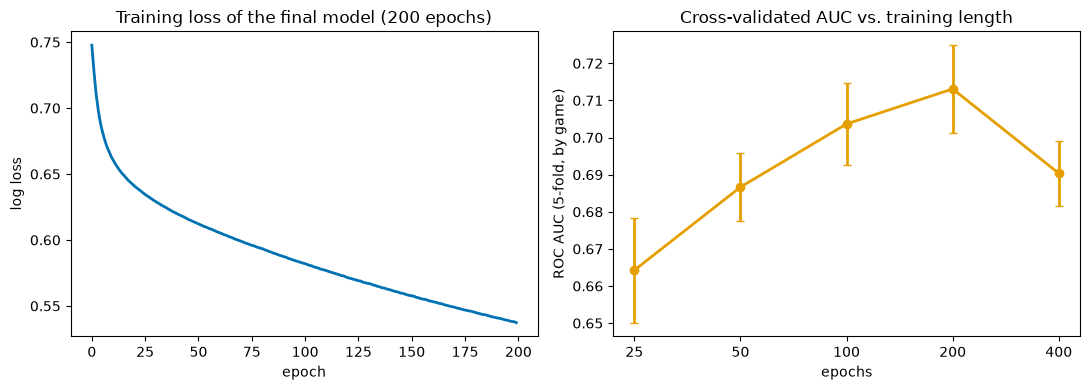

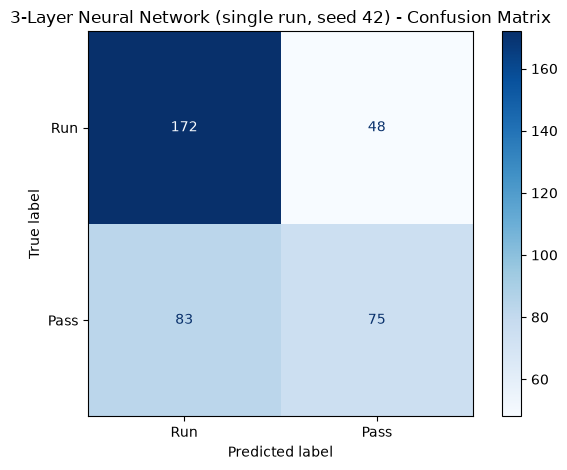

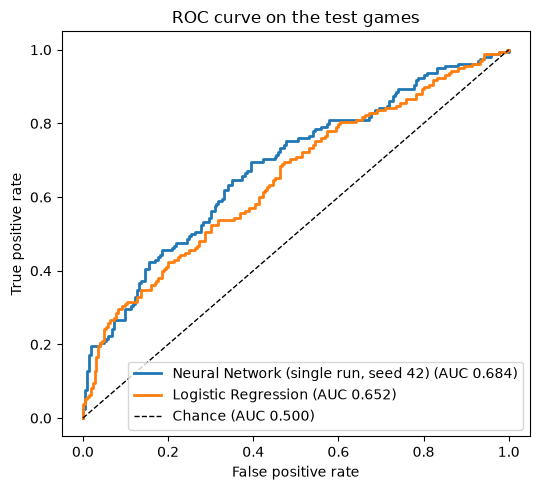

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(net.loss_curve_, color="#0072B2", lw=2)
axes[0].set_title(f"Training loss of the final model ({net.n_iter_} epochs)")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("log loss")

same = cv_table[(cv_table["hidden_nodes"] == best_params["hidden_layer_sizes"][0]) &
                (cv_table["activation"] == best_params["activation"]) &
                (cv_table["alpha"] == best_params["alpha"])].sort_values("epochs")
axes[1].errorbar(range(len(same)), same["CV AUC (mean)"], yerr=same["CV AUC (std across folds)"],
                 marker="o", color="#E69F00", lw=2, capsize=3)
axes[1].set_xticks(range(len(same))); axes[1].set_xticklabels(same["epochs"].astype(int))
axes[1].set_title("Cross-validated AUC vs. training length"); axes[1].set_xlabel("epochs")
axes[1].set_ylabel("ROC AUC (5-fold, by game)")
fig.tight_layout()
fig.savefig(fig_dir / "classification_nn_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# These two figures show ONE run (random_state=42). The averages over 10 starts are in the seed-spread table below.
plot_confusion(y_test, nn_pred, "3-Layer Neural Network (single run, seed 42) - Confusion Matrix",
               fig_dir / "classification_nn_confusion_matrix.png")

plot_roc([("Neural Network (single run, seed 42)", y_test, nn_prob), ("Logistic Regression", y_test, lr_prob)],
         "ROC curve on the test games", fig_dir / "classification_nn_roc_curve.png")

In [10]:
METRICS = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]

seed_rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for seed in range(RANDOM_STATE, RANDOM_STATE + 10):
        m = clone(best_nn).set_params(classifier__random_state=seed).fit(X_train, y_train)
        metrics, _, _ = evaluate(m, X_test, y_test)
        seed_rows.append({"seed": seed, **metrics})

seed_df = pd.DataFrame(seed_rows).set_index("seed")
seed_summary = seed_df.agg(["mean", "std", "min", "max"]).T
display(seed_summary.round(4))
seed_summary.to_csv(table_dir / "classification_nn_seed_spread.csv")

nn_mean_metrics = seed_df[METRICS].mean().to_dict()      # typical performance of this architecture
single, avg = nn_metrics["ROC AUC"], nn_mean_metrics["ROC AUC"]
print(f"Test ROC AUC over 10 random starts: {avg:.3f} +/- {seed_df['ROC AUC'].std():.3f} "
      f"(range {seed_df['ROC AUC'].min():.3f} to {seed_df['ROC AUC'].max():.3f})")
print(f"The single run shown above (seed {RANDOM_STATE}) scored {single:.3f}; logistic regression scored {lr_metrics['ROC AUC']:.3f}.")
rank = int((seed_df["ROC AUC"] > single).sum()) + 1
print(f"That run ranks #{rank} of 10 starts.", "It is on the lucky side, so quote the average, not the single run." if rank <= 3 else "")

,mean,std,min,max
Accuracy,0.6392,0.0111,0.6164,0.6534
Precision,0.5874,0.0175,0.5520,0.6098
Recall,0.4601,0.0137,0.4367,0.4747
F1 Score,0.5160,0.0143,0.4876,0.5338
ROC AUC,0.6655,0.0107,0.6467,0.6840


Test ROC AUC over 10 random starts: 0.666 +/- 0.011 (range 0.647 to 0.684)
The single run shown above (seed 42) scored 0.684; logistic regression scored 0.652.
That run ranks #1 of 10 starts. It is on the lucky side, so quote the average, not the single run.


In [11]:
ci = bootstrap_ci(y_test, nn_pred, nn_prob)
ci_lr = bootstrap_ci(y_test, lr_pred, lr_prob)

rng = np.random.default_rng(RANDOM_STATE)
diffs = []
yt = np.asarray(y_test)
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].min() == yt[idx].max():
        continue
    diffs.append(roc_auc_score(yt[idx], nn_prob[idx]) - roc_auc_score(yt[idx], lr_prob[idx]))
diff_lo, diff_hi = np.percentile(diffs, [2.5, 97.5])

print(f"Neural Network      accuracy {nn_metrics['Accuracy']:.3f}  (95% interval {ci['Accuracy'][0]:.3f} to {ci['Accuracy'][1]:.3f})")
print(f"Neural Network      ROC AUC  {nn_metrics['ROC AUC']:.3f}  (95% interval {ci['ROC AUC'][0]:.3f} to {ci['ROC AUC'][1]:.3f})")
print(f"Logistic Regression ROC AUC  {lr_metrics['ROC AUC']:.3f}  (95% interval {ci_lr['ROC AUC'][0]:.3f} to {ci_lr['ROC AUC'][1]:.3f})")
print(f"AUC difference (network - logistic): {np.mean(diffs):+.3f}  (95% interval {diff_lo:+.3f} to {diff_hi:+.3f})")
if diff_lo > 0:
    print("-> The network is better than logistic regression beyond sampling noise.")
elif diff_hi < 0:
    print("-> The network is worse than logistic regression beyond sampling noise.")
else:
    print("-> The interval includes 0: on this test set the network and logistic regression are not clearly different.")
print(f"(Seed-42 run only. The 10-start average AUC is {nn_mean_metrics['ROC AUC']:.3f} vs {lr_metrics['ROC AUC']:.3f} for logistic regression.)")

Neural Network      accuracy 0.653  (95% interval 0.608 to 0.701)
Neural Network      ROC AUC  0.684  (95% interval 0.634 to 0.736)
Logistic Regression ROC AUC  0.652  (95% interval 0.598 to 0.704)
AUC difference (network - logistic): +0.032  (95% interval -0.001 to +0.065)
-> The interval includes 0: on this test set the network and logistic regression are not clearly different.
(Seed-42 run only. The 10-start average AUC is 0.666 vs 0.652 for logistic regression.)


## Feature importance

,Feature,AUC drop,Std
0,down,0.0517,0.0107
1,distance,0.0270,0.0113
2,pass_rate_last5,0.0251,0.0081
3,short_yardage,0.0228,0.0096
4,sec_left_game,0.0172,0.0108
5,prev_call_1,0.0117,0.0061
6,pass_rate_game_so_far,0.0098,0.0079
7,is_home,0.0097,0.0039
8,prev_yards,0.0086,0.0056
9,drive_play_num,0.0075,0.0065


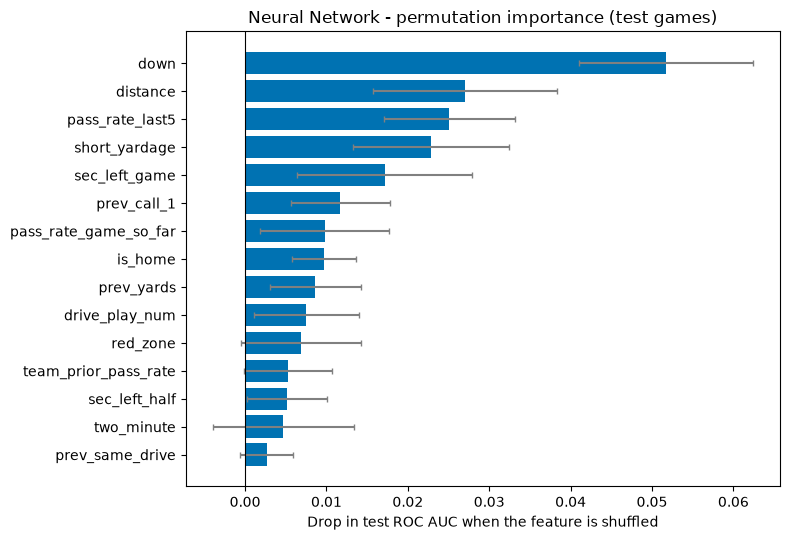

In [12]:
nn_importance = permutation_table(best_nn, X_test, y_test)
nn_importance.to_csv(table_dir / "classification_nn_permutation_importance.csv", index=False)

display(nn_importance.head(15).round(4))
plot_importance(nn_importance, "Neural Network - permutation importance (test games)",
                fig_dir / "classification_nn_permutation_importance.png")

## Save results

In [13]:
pd.DataFrame([nn_mean_metrics]).to_csv(table_dir / "classification_results_neural_network.csv", index=False)

details = {
    "best_params": {k: (list(v) if isinstance(v, tuple) else v) for k, v in best_params.items()},
    "architecture": f"{n_inputs} inputs -> {net.hidden_layer_sizes[0]} hidden ({net.activation}) -> 1 output",
    "epochs_trained": int(net.n_iter_),
    "cv_roc_auc": float(search.best_score_),
    "train_metrics": {k: float(v) for k, v in train_metrics.items()},
    "test_metrics_single_run_seed42": {k: float(v) for k, v in nn_metrics.items()},
    "test_metrics_mean_over_10_starts": {k: float(v) for k, v in nn_mean_metrics.items()},
    "test_accuracy_ci95_seed42_run": [float(x) for x in ci["Accuracy"]],
    "test_auc_ci95_seed42_run": [float(x) for x in ci["ROC AUC"]],
    "auc_diff_vs_logistic_ci95_seed42_run": [float(diff_lo), float(diff_hi)],
    "test_auc_std_over_10_starts": float(seed_df["ROC AUC"].std()),
    "tuning_seconds": round(tuning_seconds, 1),
    "single_fit_seconds": round(fit_seconds, 2),
    "random_state": RANDOM_STATE,
}
with open(table_dir / "classification_neural_network_details.json", "w") as f:
    json.dump(details, f, indent=2)

summary = pd.concat([reference, pd.DataFrame({"Neural Network (3-layer, mean of 10 starts)": nn_mean_metrics}).T])
rf_file = table_dir / "classification_results_random_forest.csv"
if rf_file.exists():
    summary.loc["Random Forest"] = pd.read_csv(rf_file).iloc[0]
display(summary.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Null Model,0.5820,0.0000,0.0000,0.0000,NaN
Logistic Regression,0.6402,0.5982,0.4241,0.4963,0.6522
"Neural Network (3-layer, mean of 10 starts)",0.6392,0.5874,0.4601,0.5160,0.6655
Random Forest,0.6667,0.6270,0.5000,0.5563,0.6787
